
### Transaction Costs

Experiment examines how proportional transaction costs affect discrete delta-hedging performance.

Transaction costs are charged at a fixed rate $c$ on the value of shares traded, including the initial hedge, subsequent rebalancing and terminal liquidation.

The terminal hedging error becomes

$$
\varepsilon_T^{(c)} = \varepsilon_T^{(0)} - cA_T
$$

where $A_T$ is the total traded value, with earlier costs accumulated to maturity.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [3]:
def calculate_d1_d2(S, K, T, r, sigma):

    d1 = (np.log(S/K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    return d1,d2

def black_scholes_price(S, K, T, r, sigma):  

    d1, d2 = calculate_d1_d2(S, K, T, r, sigma)

    C = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    P = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

    return C,P

In [4]:
S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20
rng = np.random.default_rng(4)

In [ ]:
M = 100000
batch_size = 10000

n_values = np.unique(np.append(np.geomspace(5, 500, 30).astype(int), 100))
cost_rates = [0, 0.0005, 0.001, 0.002, 0.005, 0.01]

option_premium, _ = black_scholes_price(S0, K, T, r, sigma)

results = {c: {"mean": [], "rmse": [], "std": []} for c in cost_rates}

hist_n = 100
hist_errors = {c: [] for c in cost_rates}

for n in n_values:

    t_array = np.linspace(0, T, n + 1)
    delta_t = T / n
    tau = T - t_array[:-1]

    drift = (r - 0.5 * sigma**2) * t_array
    interest = np.exp(r * tau[1:])

    stats = {c: {"sum": 0.0, "sum_sq": 0.0} for c in cost_rates}

    for start in range(0, M, batch_size):

        batch_M = min(batch_size, M - start)

        randoms = rng.normal(0, np.sqrt(delta_t), size=(batch_M, n))

        brownian = np.zeros((batch_M, n + 1))
        np.cumsum(randoms, axis=1, out=brownian[:, 1:])

        prices = S0 * np.exp(drift + sigma * brownian)

        d1, _ = calculate_d1_d2(prices[:, :-1], K, tau, r, sigma)
        delta = norm.cdf(d1)

        delta_change = np.diff(delta, axis=1)
        rebalance_cashflows = delta_change * prices[:, 1:-1]

        total_rebalance = np.sum(rebalance_cashflows * interest, axis=1)

        initial_cash = option_premium - S0 * delta[:, 0]
        terminal_cash = initial_cash * np.exp(r * T) - total_rebalance

        portfolio_value = terminal_cash + prices[:, -1] * delta[:, -1]
        call_payoff = np.maximum(prices[:, -1] - K, 0)

        error = portfolio_value - call_payoff

        initial_cost = S0 * np.abs(delta[:, 0]) * np.exp(r * T)
        rebalance_cost = np.sum(np.abs(rebalance_cashflows) * interest, axis=1)
        terminal_cost = prices[:, -1] * np.abs(delta[:, -1])

        total_traded_cost = initial_cost + rebalance_cost + terminal_cost

        for c in cost_rates:

            net_error = error - c * total_traded_cost

            stats[c]["sum"] += np.sum(net_error)
            stats[c]["sum_sq"] += np.sum(net_error**2)

            if n == hist_n:
                hist_errors[c].append(net_error)

    for c in cost_rates:

        mean = stats[c]["sum"] / M
        mean_sq = stats[c]["sum_sq"] / M

        results[c]["mean"].append(mean)
        results[c]["rmse"].append(np.sqrt(mean_sq))
        results[c]["std"].append(np.sqrt(max(0, mean_sq - mean**2)))


### Hedging Error Distributions

Terminal hedging errors are compared across different transaction-cost rates, holding the rebalancing frequency fixed at $n = 100$.

Increasing transaction costs is expected to shift the P&L distribution towards more negative values.


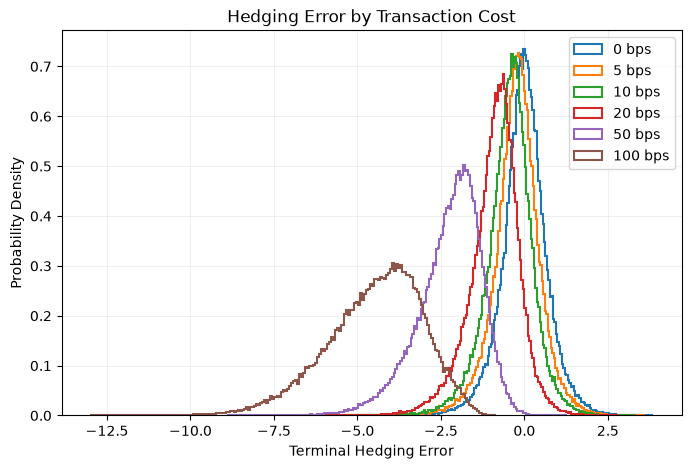

In [13]:
plt.figure(figsize=(8, 5))

for c in cost_rates:

    errors_c = np.concatenate(hist_errors[c])

    plt.hist(errors_c, bins = 200, density = True,
             histtype = "step", linewidth = 1.5,
             label = f"{c * 10000:g} bps")

plt.xlabel("Terminal Hedging Error")
plt.ylabel("Probability Density")
plt.title("Hedging Error by Transaction Cost")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


### Rebalancing Frequency and RMSE

RMSE is evaluated across increasing rebalancing frequencies and transaction-cost rates.

More frequent rebalancing reduces discretisation error but increases trading expenses. The optimal rebalancing frequency is identified by minimising RMSE over the tested values of $n$.


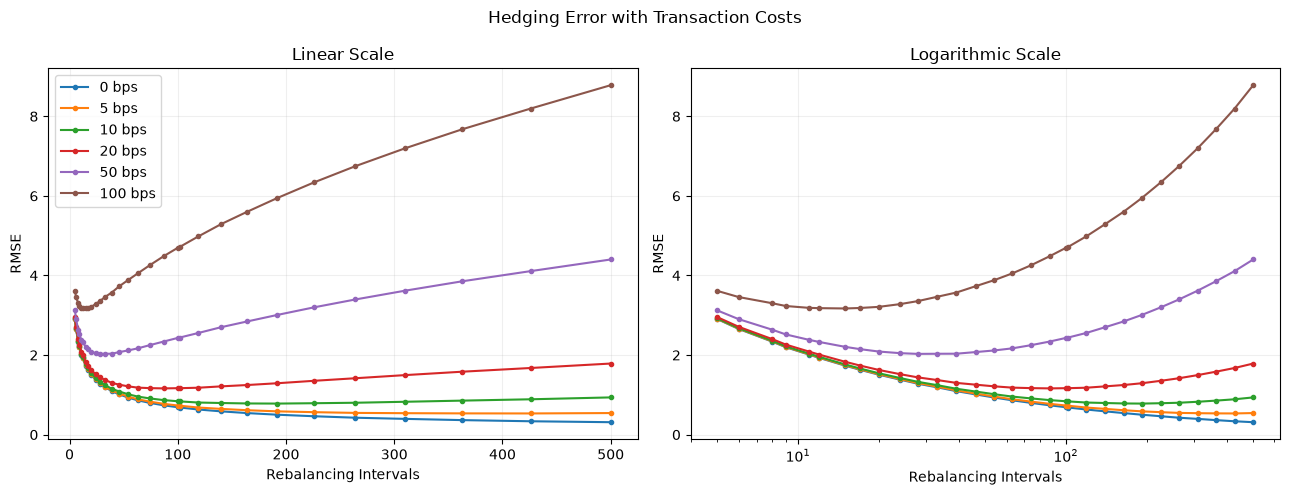

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for c in cost_rates:
    for ax in axes:
        ax.plot(n_values, results[c]["rmse"],
                marker="o", markersize=3,
                label=f"{c * 10000:g} bps")

for ax in axes:
    ax.set_xlabel("Rebalancing Intervals")
    ax.set_ylabel("RMSE")
    ax.grid(alpha=0.2)

axes[0].set_title("Linear Scale")
axes[1].set_title("Logarithmic Scale")
axes[1].set_xscale("log")

axes[0].legend()

fig.suptitle("Hedging Error with Transaction Costs")
plt.tight_layout()
plt.show()


In [15]:
for c in cost_rates:
    i = np.argmin(results[c]["rmse"])
    print(f"{c*10000:g} bps: n = {n_values[i]}, RMSE = {results[c]['rmse'][i]:.4f}")

0 bps: n = 500, RMSE = 0.3123
5 bps: n = 426, RMSE = 0.5323
10 bps: n = 192, RMSE = 0.7803
20 bps: n = 87, RMSE = 1.1619
50 bps: n = 28, RMSE = 2.0293
100 bps: n = 15, RMSE = 3.1705



### Results

Transaction costs introduce a negative bias in terminal hedging P&L: larger costs produce greater losses.

Unlike frictionless hedging, increasing rebalancing frequency does not always improve performance. RMSE curves demonstrate a trade-off between discretisation error and accumulated transaction costs, with higher costs generally favouring less frequent rebalancing.
